This notebook reproduces Fig. 16. We compute the numerical rank of the Gram matrix, defined as $G_{ij} = \langle f_i | f_j\rangle$ (see `Fig06-function_approximation.ipynb` for more information), versus the number of basis elements. The basis elements are the Landau-Zener pulses for $n_+$ between $-|n_+|_\mathrm{max}$ and $|n_+|_\mathrm{max}$. The numerical rank is obtained from a QR decomposition with pivoting, counting the diagonal elements with $|R_{ii}|>10^{-10}$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from parameterrun import parameterrun
from scipy.linalg import qr

from HQUAD_lib.QUAD_utils import solve_LZ
from HQUAD_lib.utils import gram_matrix

In [2]:
alphas = np.linspace(-25, 25, 1001)
beta = 0
ns_plus = (alphas + beta) / 2

zs_sol = np.asarray(parameterrun(solve_LZ, "alpha", alphas, beta=beta, reduction=3))
s = np.linspace(0, 1, len(zs_sol[0]))

N = len(zs_sol)
G = gram_matrix(zs_sol, s[1] - s[0])

solve_LZ: [['alpha']]:   0%|          | 0/1001 [00:00<?, ?it/s]

In [3]:
def get_rank(G: np.ndarray, size: int, tolerance: float = 1e-10) -> int:
    """Rank of the Gram matrix for the size basis elements around n_+ = 0"""
    indices = np.arange(-size // 2, size // 2) + N // 2

    G_2 = G[indices][:, indices]
    _, R, _ = qr(G_2, pivoting=True)

    return int(np.sum(np.abs(np.diag(R)) > tolerance))

In [4]:
sizes = np.arange(1, N)
ranks = np.asarray(parameterrun(get_rank, "size", sizes, G=G))

get_rank: [['size']]:   0%|          | 0/1000 [00:00<?, ?it/s]

# Plot

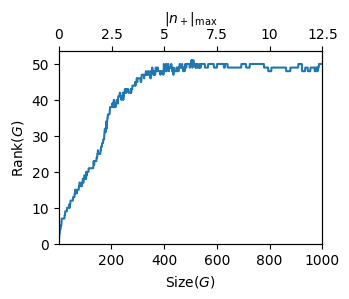

In [5]:
fig, ax = plt.subplots(figsize=(3.4, 2.5))

ax.plot(sizes, ranks, "-")
ax.set_xlim(min(sizes), max(sizes))
ax.set_ylim(0, max(ranks) * 1.05)

ax.set_xlabel(r"$\operatorname{Size}(G)$")
ax.set_ylabel(r"$\operatorname{Rank}(G)$")

# Upper axis with the maximum value of |n_+| included in the basis
ax2 = ax.twiny()
ax2.set_xbound(*ax.get_xbound())
ax2.set_xticks(ax.get_xticks())
ax2.set_xticklabels(
    [f"{tick:g}" for tick in ax.get_xticks() / np.max(sizes) * np.max(ns_plus)]
)
ax2.set_xlabel(r"$|n_+|_{\max}$");